In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline


In [13]:
df = pd.read_csv(r"C:\Users\Jyothi Kattumuri\downloads\madhu k\data\mumbai.csv")

In [14]:
df.isnull().sum()


price                  0
Address                0
area                   0
latitude               0
longitude              0
Bedrooms               0
Bathrooms              0
Balcony             3879
Status               481
neworold               0
parking             4126
Furnished_status    2655
Lift                4577
Landmarks           3638
type_of_building       0
desc                   0
Price_sqft             0
dtype: int64

In [15]:
df['Furnished_status'].unique()

<ArrowStringArray>
[nan, 'Unfurnished', 'Semi-Furnished', 'Furnished']
Length: 4, dtype: str

In [16]:
df['Furnished_status'] = df['Furnished_status'].map({'Unfurnished': 1, 'Semi-Furnished': 2, 'Furnished': 3}) #converting categorical data to numerical data


In [17]:
df.head()

,price,Address,area,latitude,longitude,Bedrooms,Bathrooms,Balcony,Status,neworold,parking,Furnished_status,Lift,Landmarks,type_of_building,desc,Price_sqft
0,22400000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",629.0,19.032800,72.896357,2.0,2.0,NaN,Under Construction,New Property,NaN,NaN,2.0,NaN,Flat,\n\n\n Right fr...,35612.082671
1,35000000.0,"Chembur, Mumbai - Harbour Line, Maharashtra",974.0,19.032800,72.896357,3.0,2.0,NaN,Under Construction,New Property,NaN,NaN,2.0,NaN,Flat,\n\n\n Right fr...,35934.291581
2,31700000.0,"Ghatkopar East, Mumbai - Central Line, Maharas...",968.0,19.085600,72.909277,3.0,3.0,NaN,Under Construction,New Property,1.0,NaN,2.0,NaN,Flat,\n \n \n...,32747.933884
3,18700000.0,"Plot Number 283, Road Number 3, Jawahar Nagar,...",629.0,19.155756,72.846862,2.0,2.0,2.0,Ready to Move,New Property,1.0,NaN,3.0,Laxmi Callista,Flat,\n\n\n Welcome ...,29729.729730
4,13500000.0,"malad east, Malad East, Mumbai - North Mumbai,...",1090.0,19.177555,72.849887,2.0,2.0,NaN,NaN,New Property,1.0,1.0,2.0,near uper govind nagar,Flat,\n \n \n...,12385.321101


In [18]:
df.drop('desc', axis=1, inplace=True) #dropping description as it is not required and has many inconsistenies in data
df.drop('Landmarks', axis=1, inplace=True) #dropping landmarks as it is not required


In [19]:
df.Bathrooms.unique()

array([ 2.,  3.,  4.,  5.,  6.,  7.,  8., 10.,  0.])

In [20]:
column_names = df.columns
print(column_names)


Index(['price', 'Address', 'area', 'latitude', 'longitude', 'Bedrooms',
       'Bathrooms', 'Balcony', 'Status', 'neworold', 'parking',
       'Furnished_status', 'Lift', 'type_of_building', 'Price_sqft'],
      dtype='str')


In [22]:
df.drop('Lift', axis=1, inplace=True)
df.drop('parking', axis=1, inplace=True)

df.drop('Balcony', axis=1, inplace=True) #Dropping these columns as they have high missing values and are not important for the model
df.drop('latitude', axis=1, inplace=True)
df.drop('longitude', axis=1, inplace=True) #Dropping these columns because users do not always know the exact latitude and longitude of the house

In [23]:
df['Status'].unique()

<ArrowStringArray>
['Under Construction', 'Ready to Move', nan]
Length: 3, dtype: str

In [24]:
df['Status'] = df['Status'].map({'Under Construction': 0, 'Ready to Move': 1})


In [25]:
df['Status'].unique()

array([ 0.,  1., nan])

In [30]:
df['Status'] = df['Status'].fillna(df['Status'].mode()[0])
df['Furnished_status'] = df['Furnished_status'].fillna(df['Furnished_status'].mode()[0])

In [31]:
df['Status'].unique()

array([0., 1.])

In [32]:
df['type_of_building'].unique()

<ArrowStringArray>
['Flat', 'Individual House']
Length: 2, dtype: str

In [33]:
df['type_of_building'] = df['type_of_building'].map({'Flat': 1, 'Individual House': 2}) #converting categorical data to numerical data


In [34]:
df['type_of_building'].unique()

array([1, 2])

In [35]:
df['Address'].nunique()
df.drop('Address', axis=1, inplace=True) #Dropping address as it is not fit for the model

In [36]:
num_rows = df.shape[0]
print("Number of rows in the dataframe:", num_rows)


Number of rows in the dataframe: 6255


In [37]:
df.head()

,price,area,Bedrooms,Bathrooms,Status,neworold,Furnished_status,type_of_building,Price_sqft
0,22400000.0,629.0,2.0,2.0,0.0,New Property,1.0,1,35612.082671
1,35000000.0,974.0,3.0,2.0,0.0,New Property,1.0,1,35934.291581
2,31700000.0,968.0,3.0,3.0,0.0,New Property,1.0,1,32747.933884
3,18700000.0,629.0,2.0,2.0,1.0,New Property,1.0,1,29729.729730
4,13500000.0,1090.0,2.0,2.0,1.0,New Property,1.0,1,12385.321101


In [38]:
df['neworold'].unique()

<ArrowStringArray>
['New Property', 'Resale']
Length: 2, dtype: str

In [39]:
df['neworold'] = df['neworold'].map({'New Property': 2, 'Resale': 1}) #converting categorical data to numerical data

In [40]:
print(df.columns)

Index(['price', 'area', 'Bedrooms', 'Bathrooms', 'Status', 'neworold',
       'Furnished_status', 'type_of_building', 'Price_sqft'],
      dtype='str')


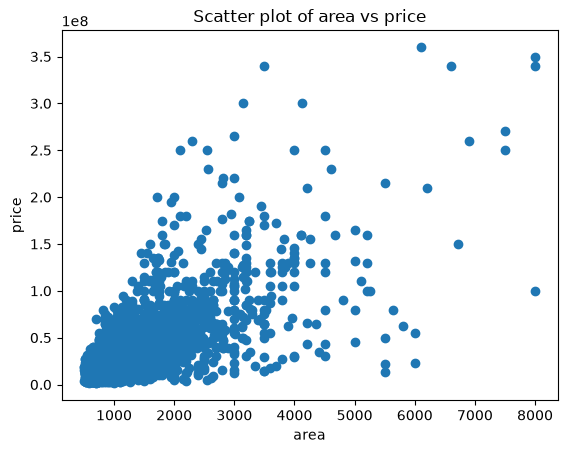

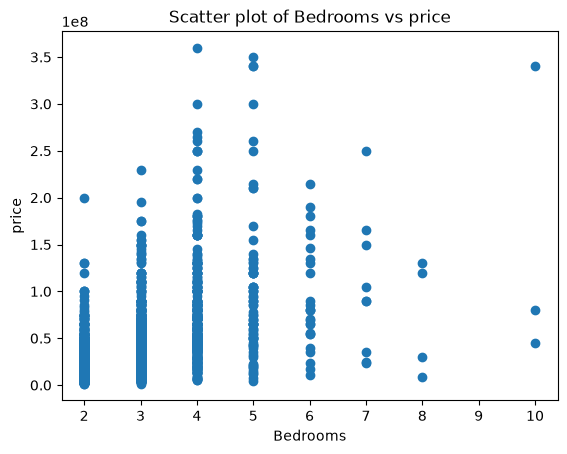

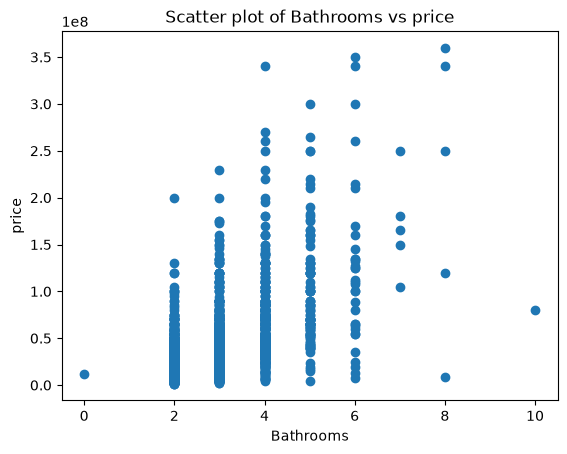

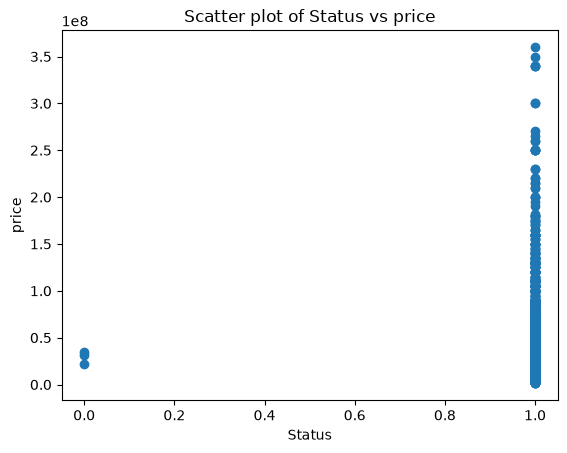

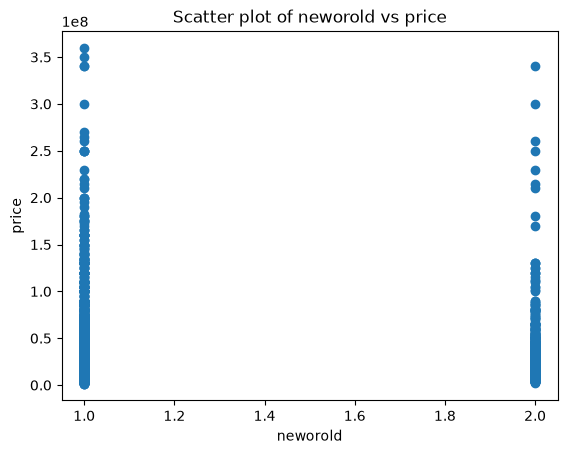

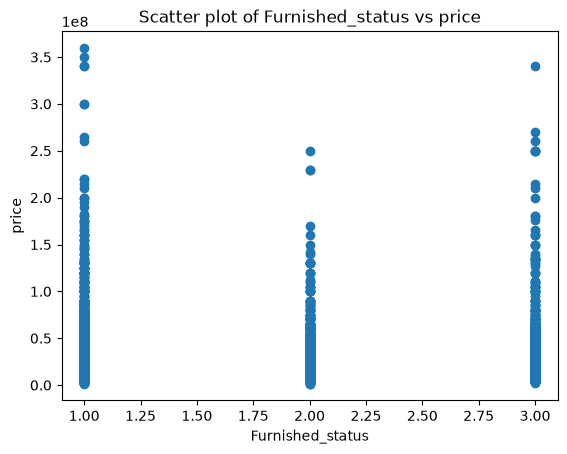

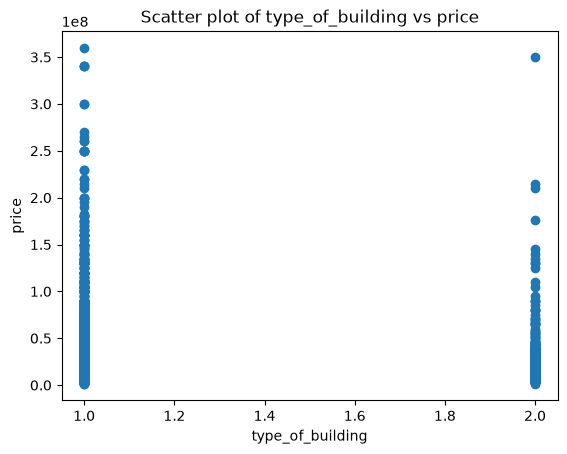

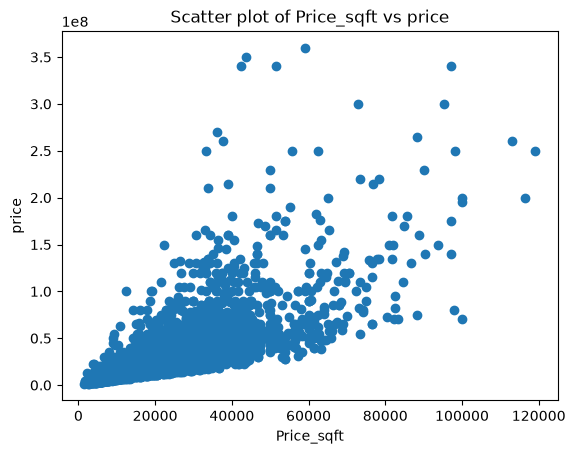

In [41]:
#inspecting relation between the features and the target variable
for feature in df.columns:
    if feature != 'price':  
        plt.scatter(df[feature], df['price'])
        plt.xlabel(feature)
        plt.ylabel('price')
        plt.title(f'Scatter plot of {feature} vs price')
        plt.show()

In [42]:
#generating correlation matrix
correlation = df.corr()['price']
print(correlation)


price               1.000000
area                0.712270
Bedrooms            0.586444
Bathrooms           0.639180
Status             -0.002245
neworold            0.037078
Furnished_status    0.065699
type_of_building    0.000008
Price_sqft          0.725421
Name: price, dtype: float64


In [43]:
df.drop('type_of_building', axis=1, inplace=True) 
df.drop('Status', axis=1, inplace=True) 
df.drop('Price_sqft', axis=1, inplace=True) #Dropping this column because if the user knows the price per square foot, they can easily calculate the price of the house defeating the purpose of the model


In [44]:
df.head()

,price,area,Bedrooms,Bathrooms,neworold,Furnished_status
0,22400000.0,629.0,2.0,2.0,2,1.0
1,35000000.0,974.0,3.0,2.0,2,1.0
2,31700000.0,968.0,3.0,3.0,2,1.0
3,18700000.0,629.0,2.0,2.0,2,1.0
4,13500000.0,1090.0,2.0,2.0,2,1.0


In [45]:
column_data_types = df.dtypes
print(column_data_types)


price               float64
area                float64
Bedrooms            float64
Bathrooms           float64
neworold              int64
Furnished_status    float64
dtype: object


In [46]:
df['Furnished_status'] = df['Furnished_status'].astype(int)
df['Bedrooms'] = df['Bedrooms'].astype(int)
df['Bathrooms'] = df['Bathrooms'].astype(int)


In [47]:
df.head()

,price,area,Bedrooms,Bathrooms,neworold,Furnished_status
0,22400000.0,629.0,2,2,2,1
1,35000000.0,974.0,3,2,2,1
2,31700000.0,968.0,3,3,2,1
3,18700000.0,629.0,2,2,2,1
4,13500000.0,1090.0,2,2,2,1


In [48]:
z_scores = np.abs((df - df.mean()) / df.std())
threshold = 3
outlier_indices = np.where(z_scores > threshold)
df = df.drop(outlier_indices[0])
df = df.reset_index(drop=True)


In [49]:
df.shape

(5956, 6)

In [53]:
df.to_csv(r'C:\Users\Jyothi Kattumuri\downloads\madhu k\data\mumbai_cleaned.csv', index=False)